<a href="https://colab.research.google.com/github/lashkami2020/Titanic-Survival-Decision-Tree/blob/main/Titanic_Survival_Prediction_Using_Decision_Tree_Classification_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Titanic Survival Prediction Using Decision Tree Classification and Hyperparameter TuningClassification

#Introduction

The sinking of the RMS Titanic in 1912 is one of the most well-known maritime disasters in history. Passenger survival was associated with several factors, including gender, age, passenger class, and family relationships.

This project applies Decision Tree Classification, a supervised machine learning algorithm, to predict whether a passenger survived the Titanic disaster based on demographic and travel-related characteristics.

The dataset contains 891 passenger records and 12 columns, including the target variable, Survived, where 0 represents passengers who did not survive and 1 represents those who survived.

The primary objectives of this project are to:

* Handle missing values and encode categorical variables.

* Build and evaluate Decision Tree models using Gini Impurity and Entropy.

* Compare model performance using Accuracy, Precision, Recall, F1-score, and Confusion Matrix.

* Identify the most influential features affecting model predictions.

* Optimize model performance using GridSearchCV and cross-validation.

* Examine the relationship between tree complexity, overfitting, and model generalization.

The dataset is divided into 80% training data and 20% testing data. Decision Tree models are trained and evaluated using Python and Scikit-learn.

The project demonstrates how an interpretable machine learning algorithm can identify patterns in historical passenger data while highlighting the importance of feature selection, model evaluation, and hyperparameter tuning.

#1. Importing Required Libraries

This project uses Python libraries for data manipulation, visualization, machine learning, and model evaluation.
- Pandas and NumPy: Used for data manipulation, numerical operations, and dataset exploration.
- Matplotlib and Seaborn: Used to visualize data distributions, relationships, and model performance.
- Scikit-learn: Provides tools for splitting the dataset, training Decision Tree classifiers, evaluating predictions, and optimizing hyperparameters.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from sklearn.tree import plot_tree
from sklearn.model_selection import GridSearchCV


##2. Load and Explore the Dataset

The Titanic dataset is loaded into a Pandas DataFrame for analysis. Initial exploration is performed to understand the dataset's structure, identify variable types, and examine descriptive statistics.

The head() function displays the first few records, info() provides information about column types and non-null values, and describe() summarizes the numerical features.

The dataset contains 891 passenger records and 12 columns, including the target variable Survived.

In [ ]:
df = pd.read_csv("/content/train (1).csv")

In [ ]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
df.shape

(891, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


##3. Handle Missing Values

In [ ]:
df.isnull().sum().sort_values()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
SibSp,0
Parch,0
Ticket,0
Fare,0
Embarked,2


In [ ]:
missing_percent = df.isnull().mean()*100
print(missing_percent)

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64


In [ ]:
df_clean = df.copy()

Drop the Cabin column
Because approximately 77% of Cabin values are missing, we will exclude it from our initial model.

In [ ]:
df_clean = df_clean.drop(['Cabin'], axis=1)

Fill missing Age values
We will use the median rather than the mean because the median is less sensitive to extreme values.

In [ ]:
df_clean["Age"]= df_clean["Age"].fillna(df_clean["Age"].median())

Step 4 — Fill missing Embarked values
Embarked is categorical, so we use its mode (most frequent value).

In [ ]:
df_clean["Embarked"]= df_clean["Embarked"].fillna(df_clean["Embarked"].mode()[0])

In [ ]:
df_clean.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


##4. Feature Selection

We will exclude PassengerId, Name, and Ticket for now.

In [ ]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']

x = df_clean[features]
y = df_clean['Survived']

print(x.head())
print(y.head())

   Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0       3    male  22.0      1      0   7.2500        S
1       1  female  38.0      1      0  71.2833        C
2       3  female  26.0      0      0   7.9250        S
3       1  female  35.0      1      0  53.1000        S
4       3    male  35.0      0      0   8.0500        S
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64


##5. Categorical Encoding
Categorical features must be converted into numerical representations before training a Decision Tree classifier using Scikit-learn.

The Sex variable is converted into binary values, with 0 representing male passengers and 1 representing female passengers.

One-Hot Encoding is applied to Embarked, creating separate binary columns for the three embarkation ports. This approach avoids introducing an artificial numerical order between categories.

In [ ]:
x = x.copy()
x['Sex'] = x['Sex'].map({'male': 0, 'female': 1})
x.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,0,22.0,1,0,7.2500,S
1,1,1,38.0,1,0,71.2833,C
2,3,1,26.0,0,0,7.9250,S
3,1,1,35.0,1,0,53.1000,S
4,3,0,35.0,0,0,8.0500,S


For Embarked, we will use One-Hot Encoding, because its categories do not have a natural numerical order.

In [ ]:
x = pd.get_dummies(
    x,
    columns=['Embarked'],
    dtype=int
)

In [ ]:
print(x.head(10))
print(x.info())

   Pclass  Sex   Age  SibSp  Parch     Fare  Embarked_C  Embarked_Q  \
0       3    0  22.0      1      0   7.2500           0           0   
1       1    1  38.0      1      0  71.2833           1           0   
2       3    1  26.0      0      0   7.9250           0           0   
3       1    1  35.0      1      0  53.1000           0           0   
4       3    0  35.0      0      0   8.0500           0           0   
5       3    0  28.0      0      0   8.4583           0           1   
6       1    0  54.0      0      0  51.8625           0           0   
7       3    0   2.0      3      1  21.0750           0           0   
8       3    1  27.0      0      2  11.1333           0           0   
9       2    1  14.0      1      0  30.0708           1           0   

   Embarked_S  
0           1  
1           0  
2           1  
3           1  
4           1  
5           0  
6           1  
7           1  
8           1  
9           0  
<class 'pandas.core.frame.DataFrame'>
Rang

In [ ]:
df['Survived'].value_counts()

,count
Survived,
0,549
1,342


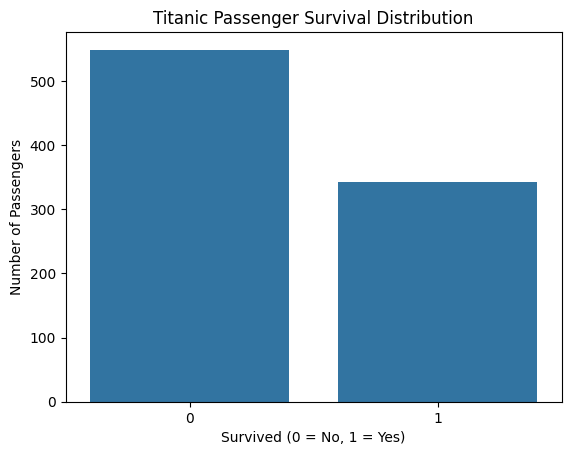

In [ ]:
sns.countplot(data=df, x='Survived')

plt.title('Titanic Passenger Survival Distribution')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')

plt.show()

##6. Train/Test Split
Next, we divide the data into training and testing sets.

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
      stratify=y
)

print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(712, 9)
(179, 9)
(712,)
(179,)


##7. Decision Tree Classification — Gini and Entropy

Two Decision Tree classifiers are developed using different splitting criteria: Gini Impurity and Entropy.

Both models are initially trained with a maximum depth of three to limit complexity and support interpretation.

Gini Impurity measures class mixing within a node, while Entropy measures uncertainty in the class distribution. Both criteria aim to identify splits that produce more homogeneous groups.

The models are trained on the same dataset to compare how the choice of splitting criterion affects classification performance.

In [ ]:
dt_gini = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=42
)
dt_gini.fit(x_train, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [ ]:
dt_entropy = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=3,
    random_state=42
)

dt_entropy.fit(x_train, y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)

##8. Model Prediction and Accuracy

In [ ]:
gini_pred= dt_gini.predict(x_test)
entropy_pred= dt_entropy.predict(x_test)

print("Gini Accuracy:",
      accuracy_score(y_test, gini_pred))

print("Entropy Accuracy:",
      accuracy_score(y_test, entropy_pred))

Gini Accuracy: 0.7932960893854749
Entropy Accuracy: 0.8044692737430168


In [ ]:
print("Gini Training Accuracy:",
      dt_gini.score(x_train, y_train))

print("Gini Testing Accuracy:",
      dt_gini.score(x_test, y_test))

print("Entropy Training Accuracy:",
      dt_entropy.score(x_train, y_train))

print("Entropy Testing Accuracy:",
      dt_entropy.score(x_test, y_test))

Gini Training Accuracy: 0.8328651685393258
Gini Testing Accuracy: 0.7932960893854749
Entropy Training Accuracy: 0.8258426966292135
Entropy Testing Accuracy: 0.8044692737430168


Text(0.5, 1.0, 'Decision Tree - Entropy')

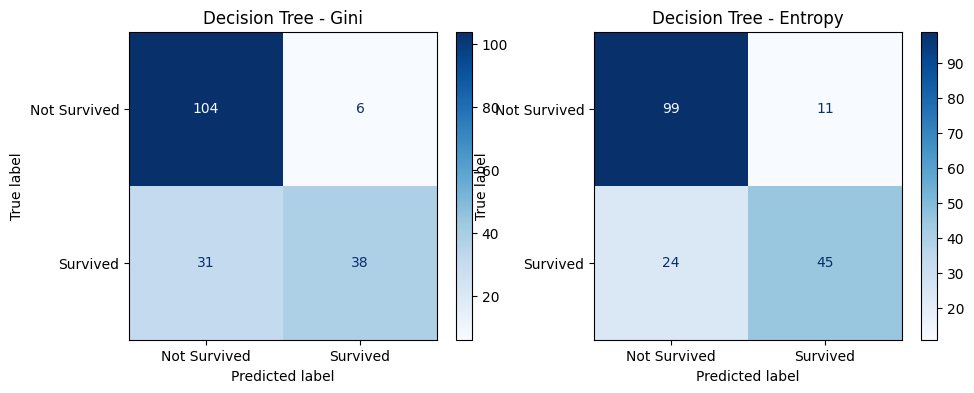

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, gini_pred,
    display_labels=['Not Survived', 'Survived'],
    ax=axes[0],
    cmap='Blues'
)
axes[0].set_title('Decision Tree - Gini')

ConfusionMatrixDisplay.from_predictions(
    y_test, entropy_pred,
    display_labels=['Not Survived', 'Survived'],
    ax=axes[1],
    cmap='Blues'
)
axes[1].set_title('Decision Tree - Entropy')

In [ ]:
from sklearn.metrics import classification_report

print("Gini Classification Report:")
print(classification_report(y_test, gini_pred))

print("\nEntropy Classification Report:")
print(classification_report(y_test, entropy_pred))

Gini Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.95      0.85       110
           1       0.86      0.55      0.67        69

    accuracy                           0.79       179
   macro avg       0.82      0.75      0.76       179
weighted avg       0.81      0.79      0.78       179


Entropy Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.90      0.85       110
           1       0.80      0.65      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.78       179
weighted avg       0.80      0.80      0.80       179



In [ ]:
from sklearn.metrics import confusion_matrix

print("Gini Confusion Matrix:")
print(confusion_matrix(y_test, gini_pred))

print("\nEntropy Confusion Matrix:")
print(confusion_matrix(y_test, entropy_pred))

Gini Confusion Matrix:
[[104   6]
 [ 31  38]]

Entropy Confusion Matrix:
[[99 11]
 [24 45]]


##9. Decision Tree Visualization

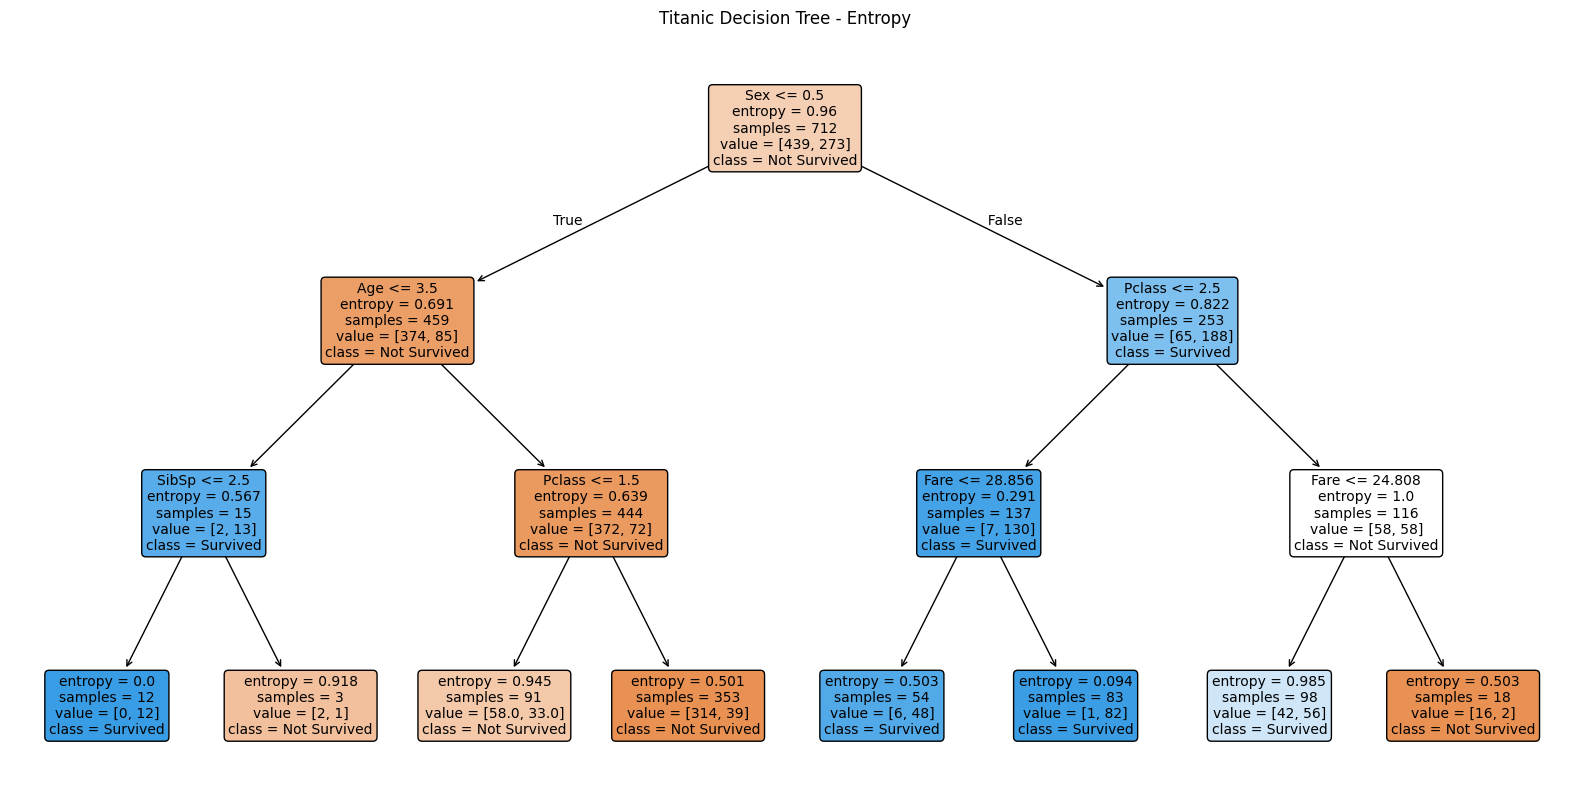

In [ ]:
plt.figure(figsize=(20, 10))

plot_tree(
    dt_entropy,
    feature_names = x_train.columns,
    class_names=['Not Survived', 'Survived'],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title('Titanic Decision Tree - Entropy')
plt.show()

##10.Feature Importance

Feature importance is calculated to identify which variables contribute most to the Decision Tree's predictions.

The initial Entropy model identifies Sex as the most influential feature, with an importance score of 57.13%, followed by Pclass at 26.33%.

Age contributes 8.97%, Fare contributes 5.50%, and SibSp contributes 2.07%.

Parch and Embarked receive importance scores of zero because they are not used in the splitting rules of this particular tree.

These scores represent contributions to impurity reduction rather than causal effects on passenger survival.

Sex           0.571300
Pclass        0.263288
Age           0.089674
Fare          0.055044
SibSp         0.020694
Parch         0.000000
Embarked_C    0.000000
Embarked_Q    0.000000
Embarked_S    0.000000
dtype: float64


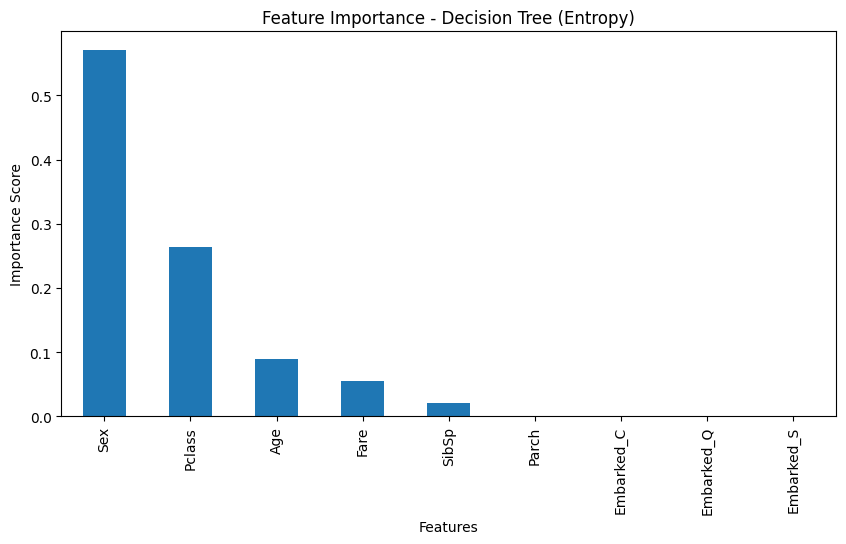

In [ ]:
importance = pd.Series(
    dt_entropy.feature_importances_,
    index=x_train.columns
).sort_values(ascending=False)

print(importance)

importance.plot(kind='bar', figsize=(10, 5))

plt.title('Feature Importance - Decision Tree (Entropy)')
plt.xlabel('Features')
plt.ylabel('Importance Score')
plt.show()

##11.Hyperparameter Tuning with GridSearchCV

GridSearchCV is applied to optimize the Decision Tree's hyperparameters and improve predictive performance.

The search evaluates different combinations of splitting criterion, maximum tree depth, minimum samples required for a split, and minimum samples per leaf.

Five-fold cross-validation is used to estimate performance across multiple training and validation subsets.

The best configuration in the initial experiment uses Gini Impurity, a maximum depth of eight, a minimum of five samples for splitting, and a minimum of one sample per leaf.

The optimized model achieves a mean cross-validation accuracy of 82.74%.

In [ ]:
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [2, 3, 4, 5, 6, 8, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5, 10]
}

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [2, 3, 4, 5, 6, 8, 10],
                         'min_samples_leaf': [1, 2, 5, 10],
                         'min_samples_split': [2, 5, 10]},
             scoring='accuracy')

In [ ]:
print("Best Parameters:")
print(grid_search.best_params_)

print("Best Cross-Validation Accuracy:")
print(grid_search.best_score_)

Best Parameters:
{'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 1, 'min_samples_split': 5}
Best Cross-Validation Accuracy:
0.8273810696345908


In [ ]:
best_tree = grid_search.best_estimator_

print("Training Accuracy:",
      best_tree.score(x_train, y_train))

print("Testing Accuracy:",
      best_tree.score(x_test, y_test))

Training Accuracy: 0.9115168539325843
Testing Accuracy: 0.8212290502793296


In [ ]:
y_pred_tuned = best_tree.predict(x_test)

In [ ]:
print(classification_report(y_test, y_pred_tuned))

              precision    recall  f1-score   support

           0       0.82      0.90      0.86       110
           1       0.81      0.70      0.75        69

    accuracy                           0.82       179
   macro avg       0.82      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179



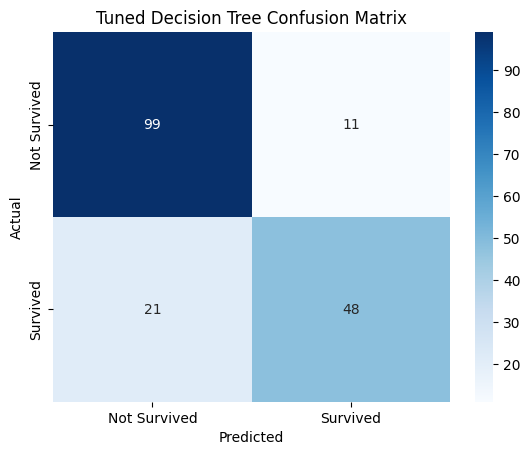

In [ ]:
cm = confusion_matrix(y_test, y_pred_tuned)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Tuned Decision Tree Confusion Matrix')
plt.show()

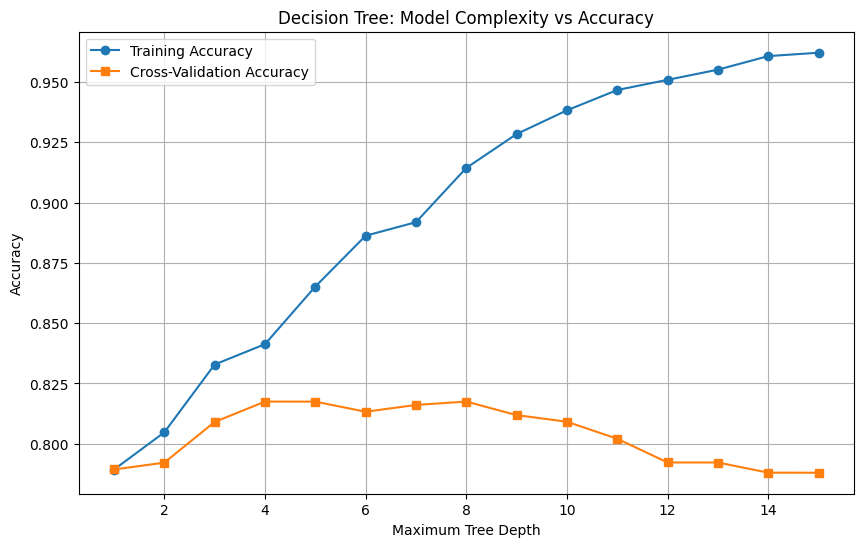

Best depth in this experiment: 8


In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import numpy as np

depths = range(1, 16)

train_scores = []
cv_scores = []

for depth in depths:

    model = DecisionTreeClassifier(
        criterion='gini',
        max_depth=depth,
        random_state=42
    )

    model.fit(x_train, y_train)

    train_scores.append(
        model.score(x_train, y_train)
    )

    scores = cross_val_score(
        model,
        x_train,
        y_train,
        cv=5,
        scoring='accuracy'
    )

    cv_scores.append(scores.mean())

plt.figure(figsize=(10, 6))

plt.plot(depths, train_scores, marker='o',
         label='Training Accuracy')

plt.plot(depths, cv_scores, marker='s',
         label='Cross-Validation Accuracy')

plt.xlabel('Maximum Tree Depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree: Model Complexity vs Accuracy')
plt.legend()
plt.grid(True)
plt.show()

print("Best depth in this experiment:",
      list(depths)[np.argmax(cv_scores)])

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

features = [
    'Pclass', 'Sex', 'Age',
    'SibSp', 'Parch', 'Fare', 'Embarked'
]

X = df[features]
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

numeric_features = [
    'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'
]

categorical_features = ['Sex', 'Embarked']

preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'),
     numeric_features),

    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

param_grid = {
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__max_depth': [2, 3, 4, 5, 6, 8, 10],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 5, 10]
}

grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV Accuracy:", grid.best_score_)
print("Test Accuracy:", grid.score(X_test, y_test))

Best Parameters: {'classifier__criterion': 'entropy', 'classifier__max_depth': 6, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2}
Best CV Accuracy: 0.8259824682359895
Test Accuracy: 0.7821229050279329


## 12. Conclusion

In this project, Decision Tree Classification was used to predict Titanic passenger survival based on demographic and travel-related features.

Two models were evaluated using Gini Impurity and Entropy, achieving testing accuracies of 79.33% and 80.45%, respectively. After hyperparameter tuning with GridSearchCV, the optimized model achieved 82.12% testing accuracy and 82.74% cross-validation accuracy.

Feature importance analysis showed that Sex and Passenger Class were the most influential predictors. The analysis also demonstrated the importance of controlling tree depth to reduce overfitting.

Overall, this project demonstrates the application of Decision Trees, model evaluation, feature importance analysis, and hyperparameter optimization in supervised machine learning.